# Computer Vision and Image Processing (CSCS111/CSDS119)
## Lab Assignment 10: Morphological Operations

**Problem:** A scanned delivery record contains unwanted specks and small gaps in character strokes. Apply morphological operations to improve readability without merging neighbouring characters.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Set plot size
plt.rcParams['figure.dpi'] = 120

### 1. Load the Document and Convert to Binary Image
We load `document_damaged.png` in grayscale and binarize using Otsu's thresholding (`THRESH_BINARY_INV + THRESH_OTSU`).
Inverting ensures character strokes are treated as foreground (`255`) and paper background as `0` for OpenCV morphological operations.

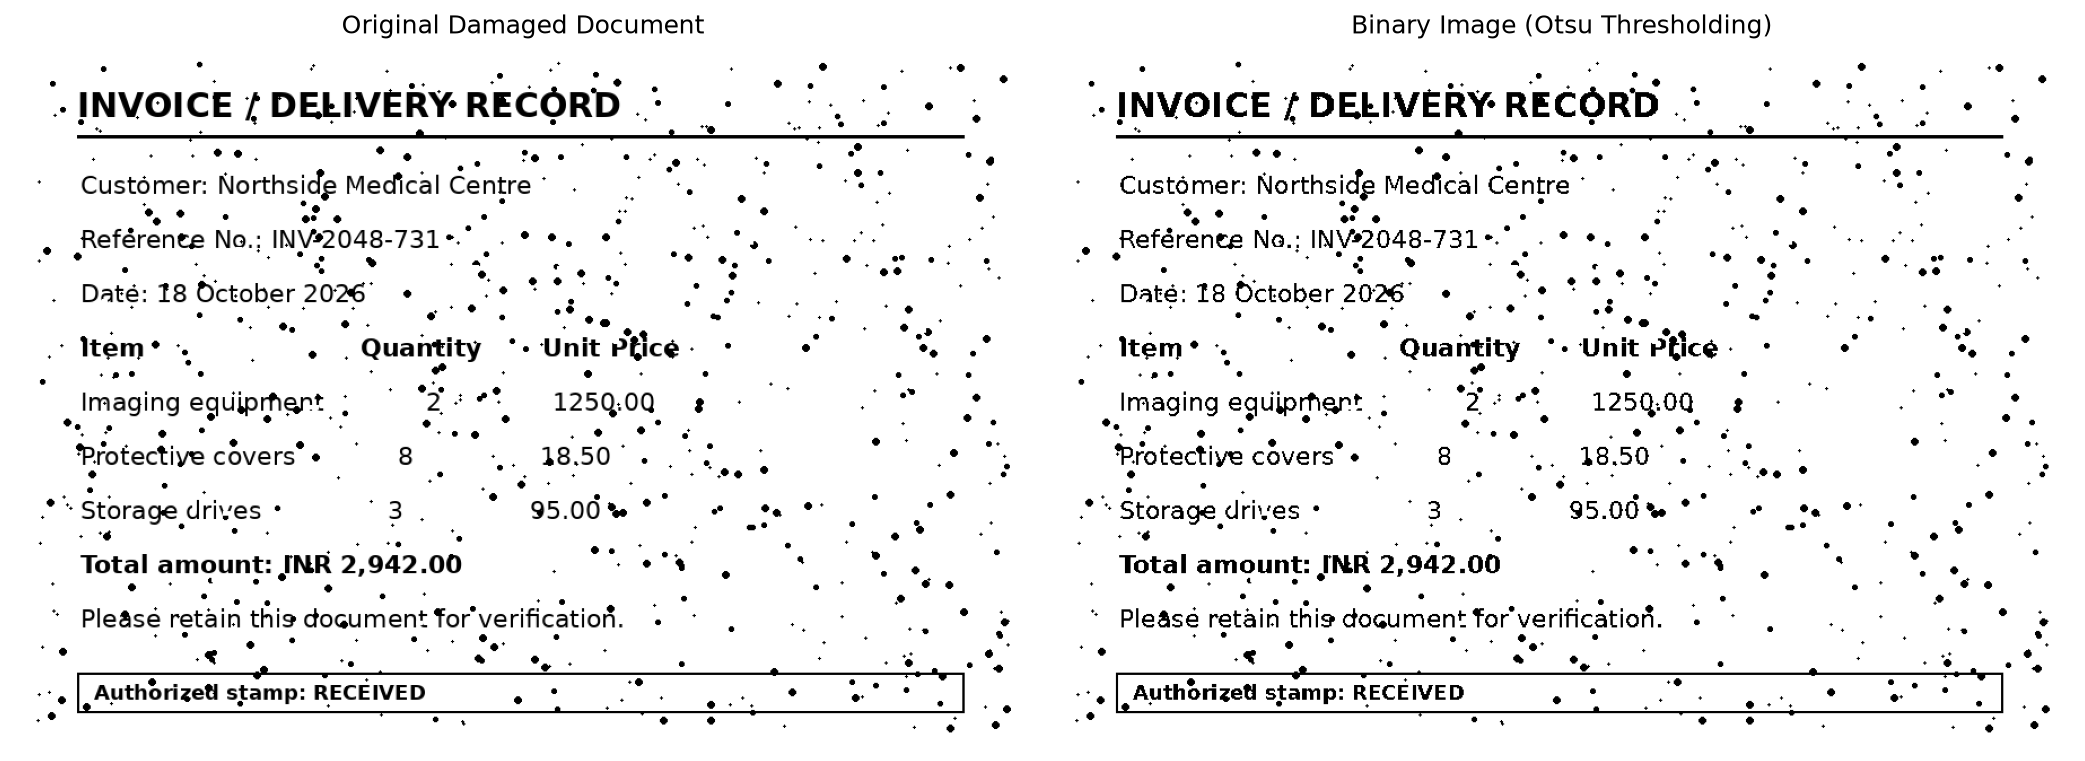

In [2]:
# Load damaged document in grayscale
img_gray = cv2.imread('document_damaged.png', cv2.IMREAD_GRAYSCALE)

# Apply Otsu's thresholding (inverted for morphology)
_, binary_inv = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Display original and binary images
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.title('Original Damaged Document')
plt.imshow(img_gray, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Binary Image (Otsu Thresholding)')
plt.imshow(cv2.bitwise_not(binary_inv), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### 2. Multi-scale Opening and Closing Evaluation
We evaluate **Opening** (erosion followed by dilation) and **Closing** (dilation followed by erosion) using two rectangular kernel sizes: `2x2` and `3x3`.
- **Opening** removes isolated specks (noise dots).
- **Closing** fills small gaps in character strokes.

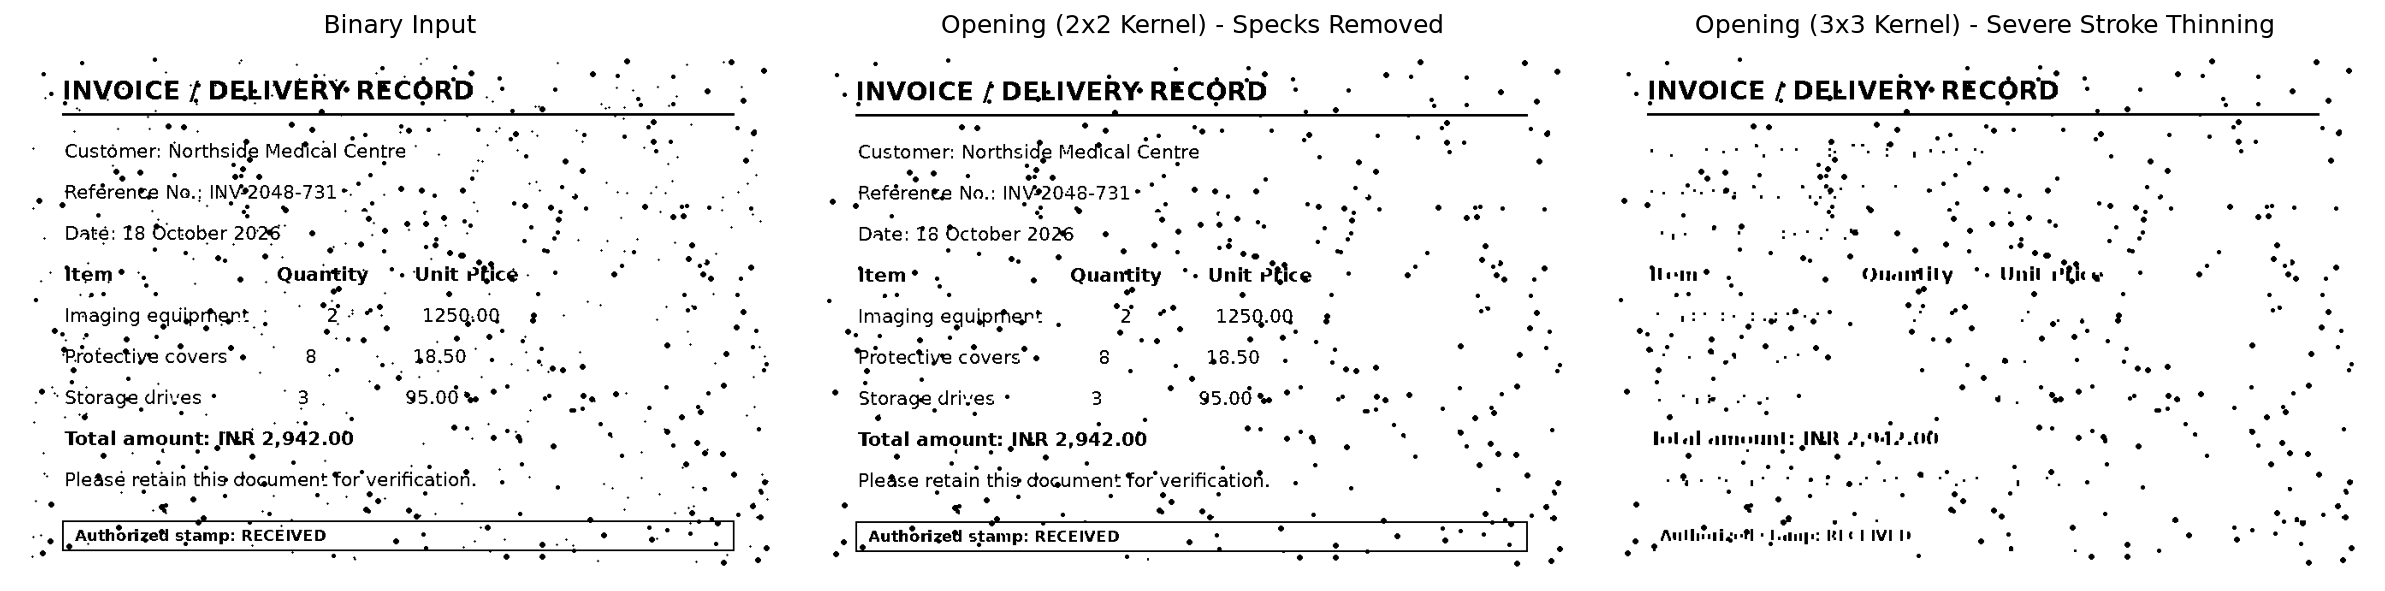

In [3]:
# Define structuring elements (rectangular kernels)
k2 = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
k3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Apply Opening with 2x2 and 3x3 structuring elements
opened_2 = cv2.morphologyEx(binary_inv, cv2.MORPH_OPEN, k2)
opened_3 = cv2.morphologyEx(binary_inv, cv2.MORPH_OPEN, k3)

# Display Opening results
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
plt.title('Binary Input')
plt.imshow(cv2.bitwise_not(binary_inv), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Opening (2x2 Kernel) - Specks Removed')
plt.imshow(cv2.bitwise_not(opened_2), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Opening (3x3 Kernel) - Severe Stroke Thinning')
plt.imshow(cv2.bitwise_not(opened_3), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

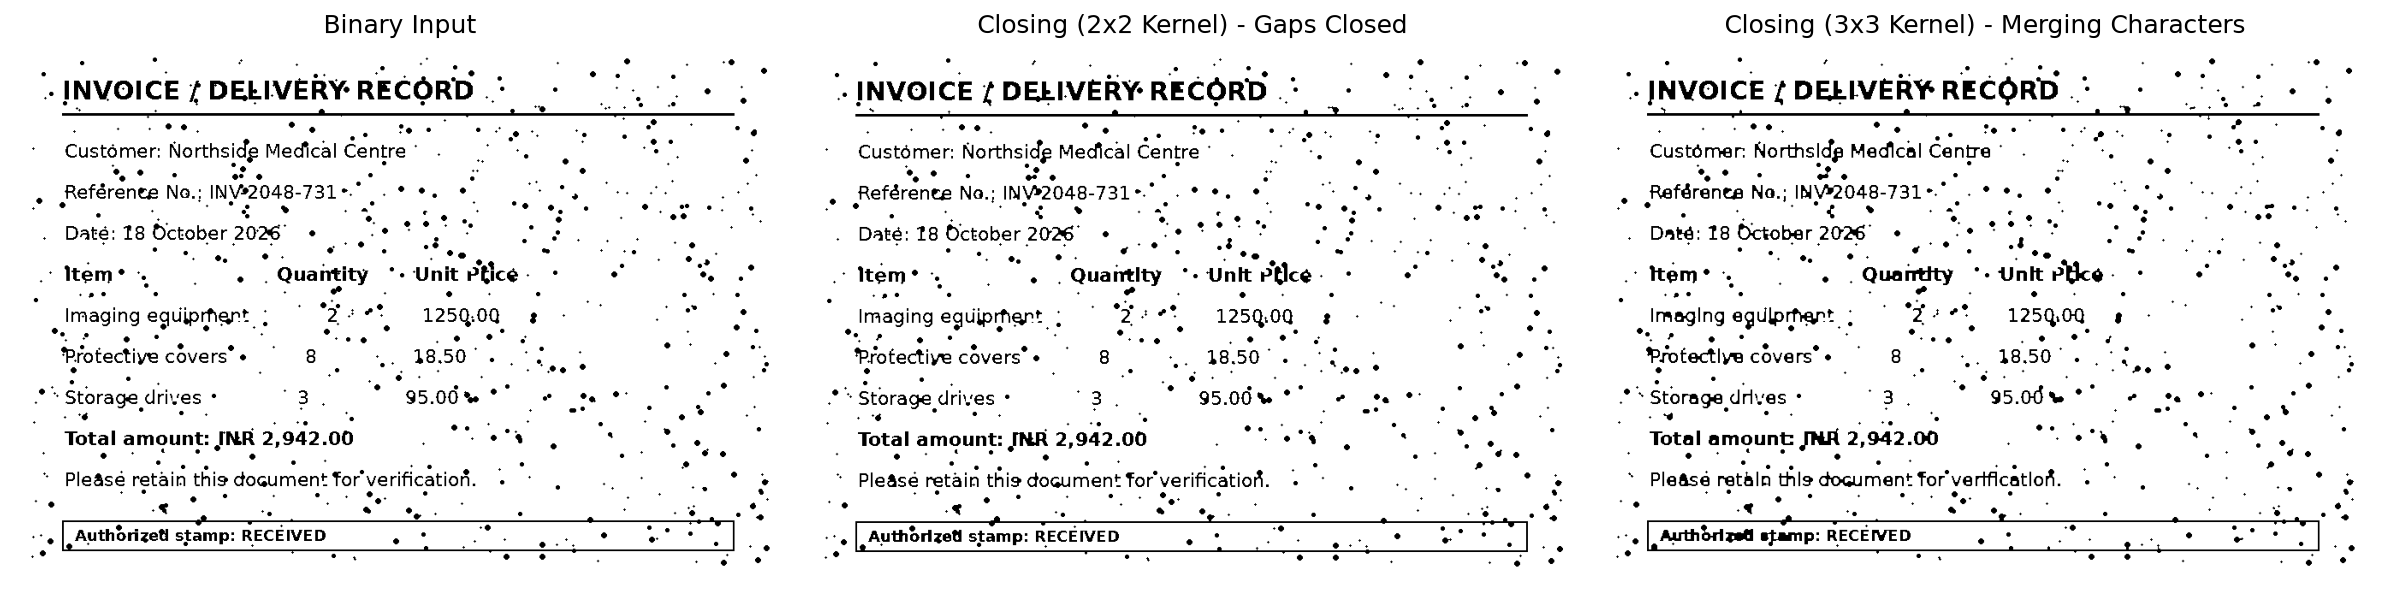

In [4]:
# Apply Closing with 2x2 and 3x3 structuring elements
closed_2 = cv2.morphologyEx(binary_inv, cv2.MORPH_CLOSE, k2)
closed_3 = cv2.morphologyEx(binary_inv, cv2.MORPH_CLOSE, k3)

# Display Closing results
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1)
plt.title('Binary Input')
plt.imshow(cv2.bitwise_not(binary_inv), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Closing (2x2 Kernel) - Gaps Closed')
plt.imshow(cv2.bitwise_not(closed_2), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Closing (3x3 Kernel) - Merging Characters')
plt.imshow(cv2.bitwise_not(closed_3), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### 3. Sequential Restoration Pipeline
We combine operations sequentially:
1. **Opening (`2x2` Kernel)**: Removes isolated background noise specks first so they are not fused into letters.
2. **Closing (`2x2` Kernel)**: Bridges small gaps within broken strokes without joining adjacent characters.

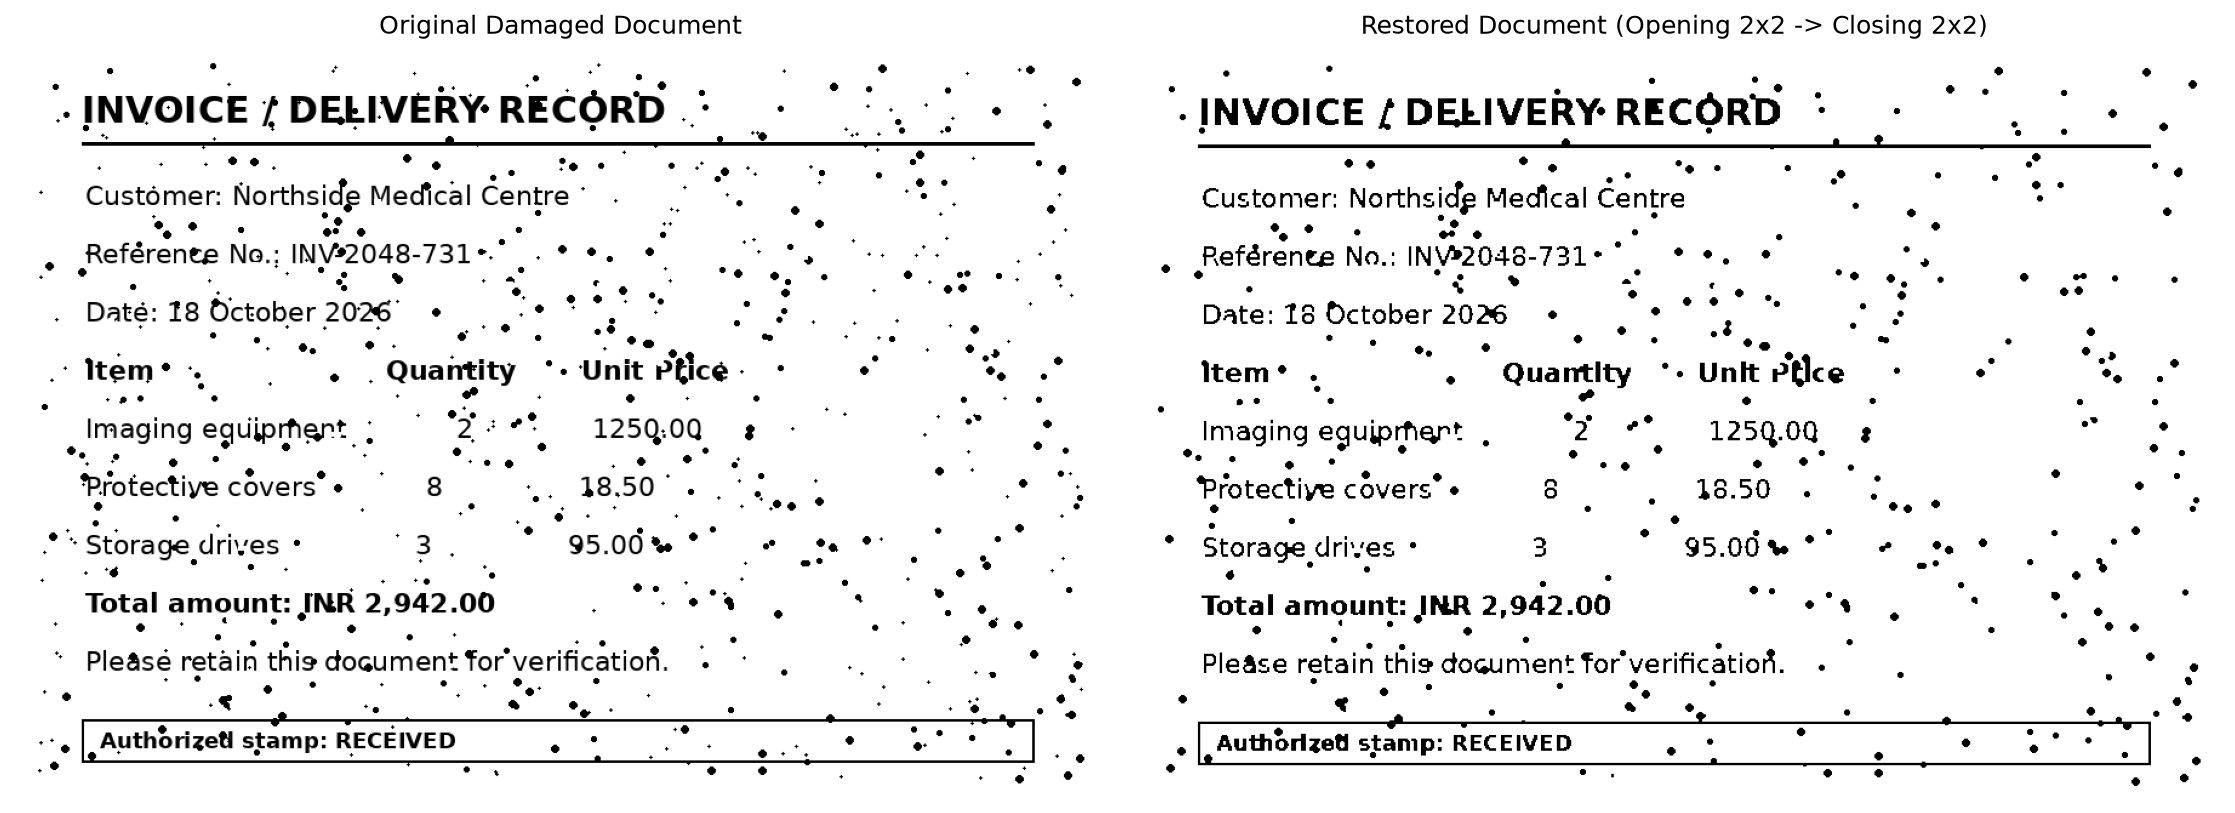

In [5]:
# Restoration sequence: Opening (2x2) followed by Closing (2x2)
denoised = cv2.morphologyEx(binary_inv, cv2.MORPH_OPEN, k2)
restored = cv2.morphologyEx(denoised, cv2.MORPH_CLOSE, k2)

# Compare Original Input with Final Restored Document
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
plt.title('Original Damaged Document', fontsize=12)
plt.imshow(img_gray, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Restored Document (Opening 2x2 -> Closing 2x2)', fontsize=12)
plt.imshow(cv2.bitwise_not(restored), cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Challenge & Compromise Analysis

**Challenge Statement:** *"A large structuring element may remove noise but also damage thin strokes or merge nearby characters. Find a reasonable compromise and explain it using your results."*

**Findings & Analysis:**
1. **Noise Removal vs. Stroke Preservation (Opening):**
   - The noise specks in the scanned document are mostly 1 pixel wide, while character strokes are approximately 1 to 2 pixels wide.
   - An opening with a **`2x2` structuring element** successfully removes almost all isolated background specks while preserving letter structures.
   - In contrast, a **`3x3` structuring element** completely erodes thin strokes (e.g. crossbars of 'e' and stems of 'r', 't', 'l'), resulting in fragmented, illegible characters (foreground pixels drop drastically from 38,446 to 23,252).

2. **Gap Closure vs. Character Merging (Closing):**
   - The gaps in character strokes are small (1 to 2 pixels), whereas the spacing between adjacent characters is only 2 to 4 pixels.
   - A closing with a **`2x2` structuring element** bridges stroke breaks without spanning the gap between neighboring characters.
   - A **`3x3` structuring element** bridges the inter-character gaps, causing adjacent letters to merge together (e.g., 'r' and 'n' merge into 'm', and 'c' merges into 'e').

**Conclusion:**
The **`2x2` rectangular structuring element** is the optimal compromise for this document resolution. Executing **Opening (`2x2`)** followed by **Closing (`2x2`)** cleans background noise and reconnects broken strokes while preserving character legibility and distinct character boundaries.